# Statistical Methods in Image Processing EE-048954
## Homework 3: Score-Based Generative Modelling
### Due Date: <span style="color:red">July 12, 2026</span>

###  Submission Guidelines

* Submission only in **pairs** on the course website (Moodle).
* Working environment:
    * We encourage you to work in `Jupyter Notebook` online using <a href="https://colab.research.google.com/">Google Colab</a> as it does not require any installation.
* You should submit two **separated** files:
    * A `.ipynb` file, with the name: `ee048954_hw4_id1_id2.ipynb` which contains your code implementations.
    * A `.pdf` file, with the name: `ee048954_hw4_id1_id2.pdf` which is your report containing plots, answers, and discussions.
    * **No handwritten submissions** and no other file-types (`.docx`, `.html`, ...) will be accepted.

### Mounting your drive for saving/loading stuff

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ModuleNotFoundError:
    pass  # not running on Colab; skip drive mount


### Importing relevant libraries

In [2]:
## Standard libraries
import numpy as np
import random

## KDE estimation
from sklearn.neighbors import KernelDensity

## Progress bar
import tqdm.notebook as tqdm

## Imports for plotting
import matplotlib.pyplot as plt
import matplotlib.animation as animation
%matplotlib inline
import matplotlib
matplotlib.rcParams['lines.linewidth'] = 2.0
plt.style.use('ggplot')

## Pytorch
import torch
import torch.nn as nn
import torch.optim as optim
import torch.autograd as autograd

# device to be used (preferably a GPU, change Colab runtime type if needed)
device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")
print("Using device", device)

Using device cpu


## Introduction

Given a probablity density function $p(\mathbf{x})$, we define the *score* as $\nabla_\mathbf{x} \log p(\mathbf{x}).$ As you might guess, score-based generative models are trained to estimate $\nabla_\mathbf{x} \log p(\mathbf{x})$.

Unlike likelihood-based models such as normalizing flows from HW1, score-based models do not have to be normalized and are easier to parameterize. For example, recall the non-normalized statistical model from HW2 $p_\theta(\mathbf{x}) = \frac{e^{-E_\theta(\mathbf{x})}}{Z_\theta}$, where $E_\theta(\mathbf{x}) \in \mathbb{R}$ is called the energy function and $Z_\theta$ is an unknown normalizing constant that makes $p_\theta(\mathbf{x})$ a proper probability density function. We saw that $E_\theta(\mathbf{x})$ can be parameterized by a flexible neural network, and computing the score $\nabla_\mathbf{x} \log p_\theta(\mathbf{x}) = -\nabla_\mathbf{x} E_\theta(\mathbf{x})$ didn't require computing the normalizing constant $Z_\theta$. Similarly, in Score Matching, any neural network that maps an input vector $\mathbf{x} \in \mathbb{R}^d$ to an output vector $\mathbf{y} \in \mathbb{R}^d$ can be used as a score-based model, as long as the output and input have the same dimensionality. This yields huge flexibility in choosing model architectures.

Recently, variants of these models (a.k.a. Diffusion Models) have obtained high-quality samples comparable to/better than GANs (e.g. [this paper](https://arxiv.org/abs/2105.05233)) without requiring adversarial training, and are considered to be the current state-of-the-art. For the sake of simplicity, as usual, we will work with a toy example to enhance our understanding of the problems that arise when trying to learn and sample scores $\nabla_\mathbf{x} \log p(\mathbf{x})$.

## Part I: Annealed Langevin Dynamics (40 points)

Consider the following Gaussian Mixture Model (GMM) distribution

$$ p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\}) = \alpha\mathcal{N}\left(\mathbf{x};\mu_1,\sigma^2 I\right) + \left(1-\alpha\right)\mathcal{N}\left(\mathbf{x};\mu_2,\sigma^2 I\right) ,$$
where $\alpha = \frac{1}{5}$, $\mathbf{x},\mu_1, \mu_2 \in \mathbb{R}^2$ with $\mu_1 = (-5,-5)^T , \mu_2 = (5,5)^T$, $\sigma^2=1$, and $I \in \mathbb{R}^{2 \times 2}$ is the identity matrix. For your convenience, we provide below the class `GMMDist`.

In [3]:
class GMMDist(object):
    def __init__(self):
        self.mix_probs = torch.tensor([0.2, 0.8])
        self.means = torch.stack([-torch.ones(2)*5, torch.ones(2)*5], dim=0)
        self.sigma = 1.

    def sample(self, n, sigma=1):
        """Draw n samples from the GMM with (per-component) std = sigma."""
        comps = torch.distributions.Categorical(self.mix_probs).sample((n,))
        chosen_means = self.means[comps]                # (n, 2)
        return chosen_means + sigma * torch.randn(n, 2)

    def log_prob(self, samples, sigma=1):
        """log p(x) evaluated pointwise. Returns (n, 1)."""
        diff = samples.unsqueeze(1) - self.means.unsqueeze(0)            # (n, 2, 2)
        log_norm = -torch.log(torch.tensor(2 * np.pi * sigma**2))        # 2D Gaussian
        log_n = -0.5 * (diff**2).sum(dim=-1) / (sigma**2) + log_norm     # (n, 2)
        log_weighted = torch.log(self.mix_probs) + log_n                 # (n, 2)
        return torch.logsumexp(log_weighted, dim=-1, keepdim=True)       # (n, 1)

    def score(self, samples, sigma=1):
        """grad_x log p(x). Returns (n, 2)."""
        diff = samples.unsqueeze(1) - self.means.unsqueeze(0)            # (n, 2, 2)
        log_norm = -torch.log(torch.tensor(2 * np.pi * sigma**2))
        log_n = -0.5 * (diff**2).sum(dim=-1) / (sigma**2) + log_norm     # (n, 2)
        log_weighted = torch.log(self.mix_probs) + log_n
        log_resp = log_weighted - torch.logsumexp(log_weighted, dim=-1, keepdim=True)
        resp = torch.exp(log_resp)                                       # (n, 2)
        # grad_x log p = -(1/sigma^2) * sum_i resp_i * (x - mu_i)
        grad_logp = -(resp.unsqueeze(-1) * diff).sum(dim=1) / (sigma**2) # (n, 2)
        return grad_logp


<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 1</span>**. How can we sample from $p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ considering $\alpha=0.2$? Implement the missing method `sample` that accepts the number of samples `n` and the standard deviation `sigma` and returns a tensor of $n \times 2$ samples $\{\mathbf{x_i}\}$. Plot $J=1000$ i.i.d. samples $\{\mathbf{x_i}\}$ from $p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$.

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 2</span>**. Write down the analytical expression for $\log p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ and implement the missing method `log_prob`. The method accepts as input two arguments: `samples` - the points at which we wish to evaluate the expression, `sigma` - the standard deviation, and returns an $n \times 1$ tensor `logp` (scalar per sample).  Using this method, plot $p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ at a 2D grid of $100\times 100$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$.

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 3</span>**. Write down the analytical expression for $\nabla_{\mathbf{x}}\log p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ and implement the missing method `score`. The method accepts as input two arguments: `samples` - the points at which we wish to evaluate the expression, `sigma` - the standard deviation, and returns an $n \times 2$ tensor `grad_logp` (2D vector per sample).  Using this method, plot the vector field $\nabla_{\mathbf{x}}\log p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ at a 2D grid of $20\times 20$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$ using a [quiver plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.quiver.html).


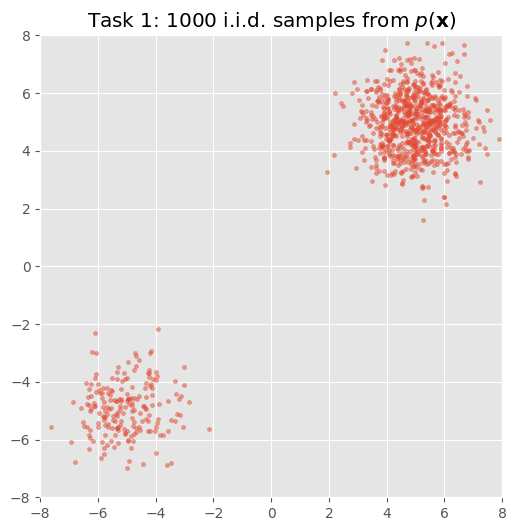

In [4]:
# Task 1 — sample plot
torch.manual_seed(0)
gmm = GMMDist()
samples_t1 = gmm.sample(1000)

plt.figure(figsize=(6, 6))
plt.scatter(samples_t1[:, 0].numpy(), samples_t1[:, 1].numpy(), s=8, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8); plt.gca().set_aspect('equal')
plt.title(r'Task 1: 1000 i.i.d. samples from $p(\mathbf{x})$')
plt.show()


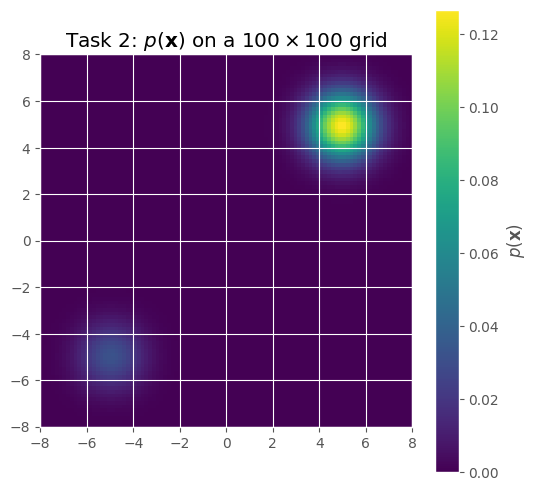

In [5]:
# Task 2 — p(x) on a 100x100 grid
xs100 = torch.linspace(-8, 8, 100)
X100, Y100 = torch.meshgrid(xs100, xs100, indexing='ij')
grid100 = torch.stack([X100.flatten(), Y100.flatten()], dim=1)
p_grid = torch.exp(gmm.log_prob(grid100)).reshape(100, 100)

plt.figure(figsize=(6, 6))
plt.imshow(p_grid.T.numpy(), origin='lower', extent=[-8, 8, -8, 8], cmap='viridis')
plt.colorbar(label=r'$p(\mathbf{x})$')
plt.title(r'Task 2: $p(\mathbf{x})$ on a $100 \times 100$ grid')
plt.show()


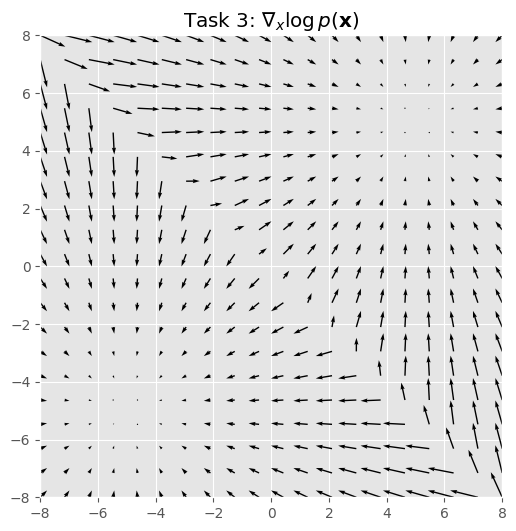

In [6]:
# Task 3 — score field on a 20x20 grid
xs20 = torch.linspace(-8, 8, 20)
X20, Y20 = torch.meshgrid(xs20, xs20, indexing='ij')
grid20 = torch.stack([X20.flatten(), Y20.flatten()], dim=1)
scores_t3 = gmm.score(grid20)

plt.figure(figsize=(6, 6))
plt.quiver(X20.numpy(), Y20.numpy(),
           scores_t3[:, 0].reshape(20, 20).numpy(),
           scores_t3[:, 1].reshape(20, 20).numpy())
plt.xlim(-8, 8); plt.ylim(-8, 8); plt.gca().set_aspect('equal')
plt.title(r'Task 3: $\nabla_x \log p(\mathbf{x})$')
plt.show()


Next, we would like to sample from $p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ assuming we **only** have access to the scores $\nabla_{\mathbf{x}}\log p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$.

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 4</span>**. Implement a function that samples $p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ using Langevin dynamics:
$$\mathbf{x}^{k+1} = \mathbf{x}^{k} + \epsilon \nabla_\mathbf{x} \log p(\mathbf{x}^k) + \sqrt{2\epsilon} \mathbf{z}^k,$$
with $\mathbf{z}^k \sim \mathcal{N}(0,I)$. This function accepts four inputs:
* `score` - a function that accepts an $n \times 2$ tensor of `samples` and a standard deviation `sigma` and returns an $n \times 2$ tensor of `scores`.
* `init` - $n \times 2$ tensor of initial positions initialized uniformly in $\left[-8,8\right]\times\left[-8,8\right]$ (i.e. $\mathbf{u_i} \sim \mathcal{U}\left[-8,8\right]^2$).
* `epsilon` - the step size of the Langevin update.
* `T` - the number of Langevin steps.

Show the resulting samples for $n=1280, \epsilon=0.05, T=1000$. Discuss the results in terms of the relative mode weight. Do you notice anything strange? What is the reason for this behavior?

Let $\{\sigma_i\}_{i=1}^L$ be a positive geometric sequence that satisfies $\frac{\sigma_1}{\sigma_2}=\dots=\frac{\sigma_
{L-1}}{\sigma_L} > 1$. The **Annealed** Langevin dynamics algorithm, proposes to sample from  $p(x)$ using $L$ successive applications of Langevin dynamics with a twist: In the $i^{\text{th}}$ application of Langevin dynamics for $T$ steps, we initialize the samples with the output of the $\left(i-1\right)^{\text{th}}$ run, update the step size according to $\epsilon_i = \epsilon \frac{\sigma_i^2}{\sigma_L^2}$, and use the scores of a noisy version of our original samples $\{\tilde{\mathbf{x}}\}$ with a probability density of $q_{\sigma_i}(\tilde{\mathbf{x}}) \triangleq \int p(\mathbf{x}) \mathcal{N}(\tilde{\mathbf{x}}|\mathbf{x},\sigma_i^2 I)d\mathbf{x}$. The sequence $\{\sigma_i\}_{i=1}^L$ is chosen such that $\sigma_1$ is large enough to mitigate the difficulties encountered in Task 4, and $\sigma_L$ is small enough to minimize the effect on the data. Note that for our Toy dataset adding Gaussian noise with $\sigma_i$ will result in the same GMM distribution with a different effective standard deviation of $\tilde{\sigma_i}=\sqrt{\sigma^2+\sigma_i^2}$. Therefore, for simplicity of implementation, we will consider the effective standard deviations $\{\tilde{\sigma}\}_{i=1}^L$ directly and implement the scores of the distribution $q_{\sigma_i}(\tilde{\mathbf{x}})$ using the class method `GMMDist.score()`. In our implementation, we will use a sequence of $L=10$ effective standard deviations $\{\tilde{\sigma}\}_{i=1}^{L}$ spaced linearly in log-space between $\tilde{\sigma}_1=20$ and $\tilde{\sigma}_L=1$. Meaning, the resulting sequence $\{\tilde{\sigma}_i\}_{i=1}^L$ can be implemented using `np.linspace()` like so: `sigmas=np.exp(np.linspace(np.log(20.),np.log(1.),10))`.

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 5</span>**. Implement a function that samples $p(\mathbf{x};\{\mu_1, \mu_2, \alpha, \sigma^2\})$ using **Annealed** Langevin dynamics summarized as follows:
* Initialize with $\mathbf{x}^0\sim\mathcal{U}\left[-8,8\right]^2$.
* For $i=1,2,\dots,L$:
    * Update the step size: $\epsilon_i = \epsilon\frac{\tilde{\sigma}_i^2}{\tilde{\sigma}_L^2}$
    * For $t=1,2,\dots,T$:
        * Draw $\mathbf{z}^t \sim \mathcal{N}\left(0,I\right)$
        * $\mathbf{x}^t = \mathbf{x}^{t-1} + \epsilon \nabla_\mathbf{x} \log p(\mathbf{x}^{t-1};\tilde{\sigma}_i^2) + \sqrt{2\epsilon} \mathbf{z}^t$
    * Update initialization $\mathbf{x}^0=\mathbf{x}^T$

This function accepts five inputs:
* `score` - a function that accepts an $n \times 2$ tensor of `samples` and a standard deviation `sigma` and returns an $n \times 2$ tensor of `scores`.
* `init` - $n \times 2$ tensor of initial positions initialized uniformly in $\left[-8,8\right]\times\left[-8,8\right]$ (i.e. $\mathbf{u_i} \sim \mathcal{U}\left[-8,8\right]^2$).
* `sigmas` - $L \times 1$ tensor of effective standard deviations in a decreasing order (i.e. `sigmas[0]` is $\tilde{\sigma}_1$).
* `epsilon` - the step size of the Langevin update.
* `T` - the number of Langevin steps.

Show the resulting samples for $n=1280, \epsilon=0.05, T=100$. Discuss the results in terms of the relative mode weight compared to Task 4. Plot the resulting samples for each annealing step $i=1,\dots,L$ (you're encouraged to create an animation), and explain the effect of using multiple standard deviations.

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 6</span>**. To enforce your conclusions from Task 5, plot the estimated probability density function from Tasks 4 and 5 at a 2D grid of $100\times 100$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$ and compare them to the result in Task 2. Your comparison should be performed both visually in 2D and along the line $x=y$ in 1D. To approximate the estimated density $\hat{p}\left(\mathbf{x}\right)$ in Tasks 4 and 5, apply kernel density estimation to the respective samples using the function `sklearn.neighbors.KernelDensity()` with `bandwidth=0.5`.



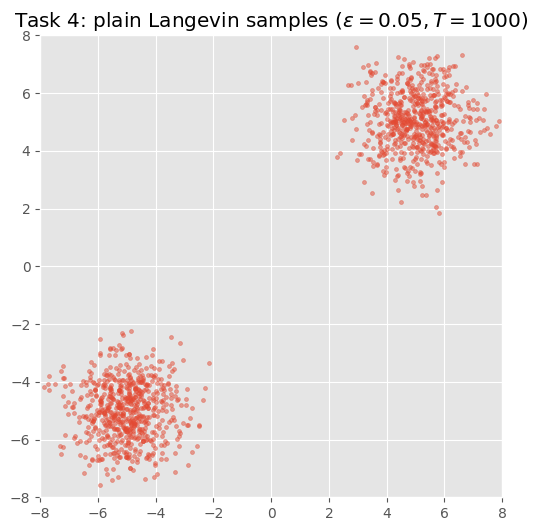

Task 4: empirical weight on small mode = 0.511 (true value: 0.20)


In [7]:
# Task 4 — plain Langevin dynamics
def langevin_dynamics(score, init, epsilon, T):
    """One run of Langevin dynamics. score(x, sigma=1) -> (n, 2)."""
    x = init.clone()
    sqrt_2eps = float(np.sqrt(2 * epsilon))
    for _ in range(T):
        z = torch.randn_like(x)
        x = x + epsilon * score(x) + sqrt_2eps * z
    return x

torch.manual_seed(0)
n = 1280
init_uniform = torch.rand(n, 2) * 16 - 8                       # U[-8, 8]^2
samples_t4 = langevin_dynamics(gmm.score, init_uniform, epsilon=0.05, T=1000)

plt.figure(figsize=(6, 6))
plt.scatter(samples_t4[:, 0].numpy(), samples_t4[:, 1].numpy(), s=8, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8); plt.gca().set_aspect('equal')
plt.title(r'Task 4: plain Langevin samples ($\epsilon=0.05, T=1000$)')
plt.show()

w_small_t4 = ((samples_t4[:, 0] < 0) & (samples_t4[:, 1] < 0)).float().mean().item()
print(f'Task 4: empirical weight on small mode = {w_small_t4:.3f} (true value: 0.20)')


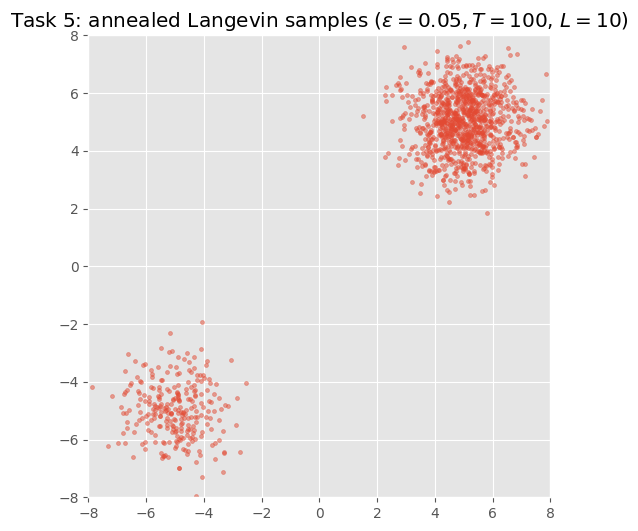

Task 5: empirical weight on small mode = 0.206 (true value: 0.20)


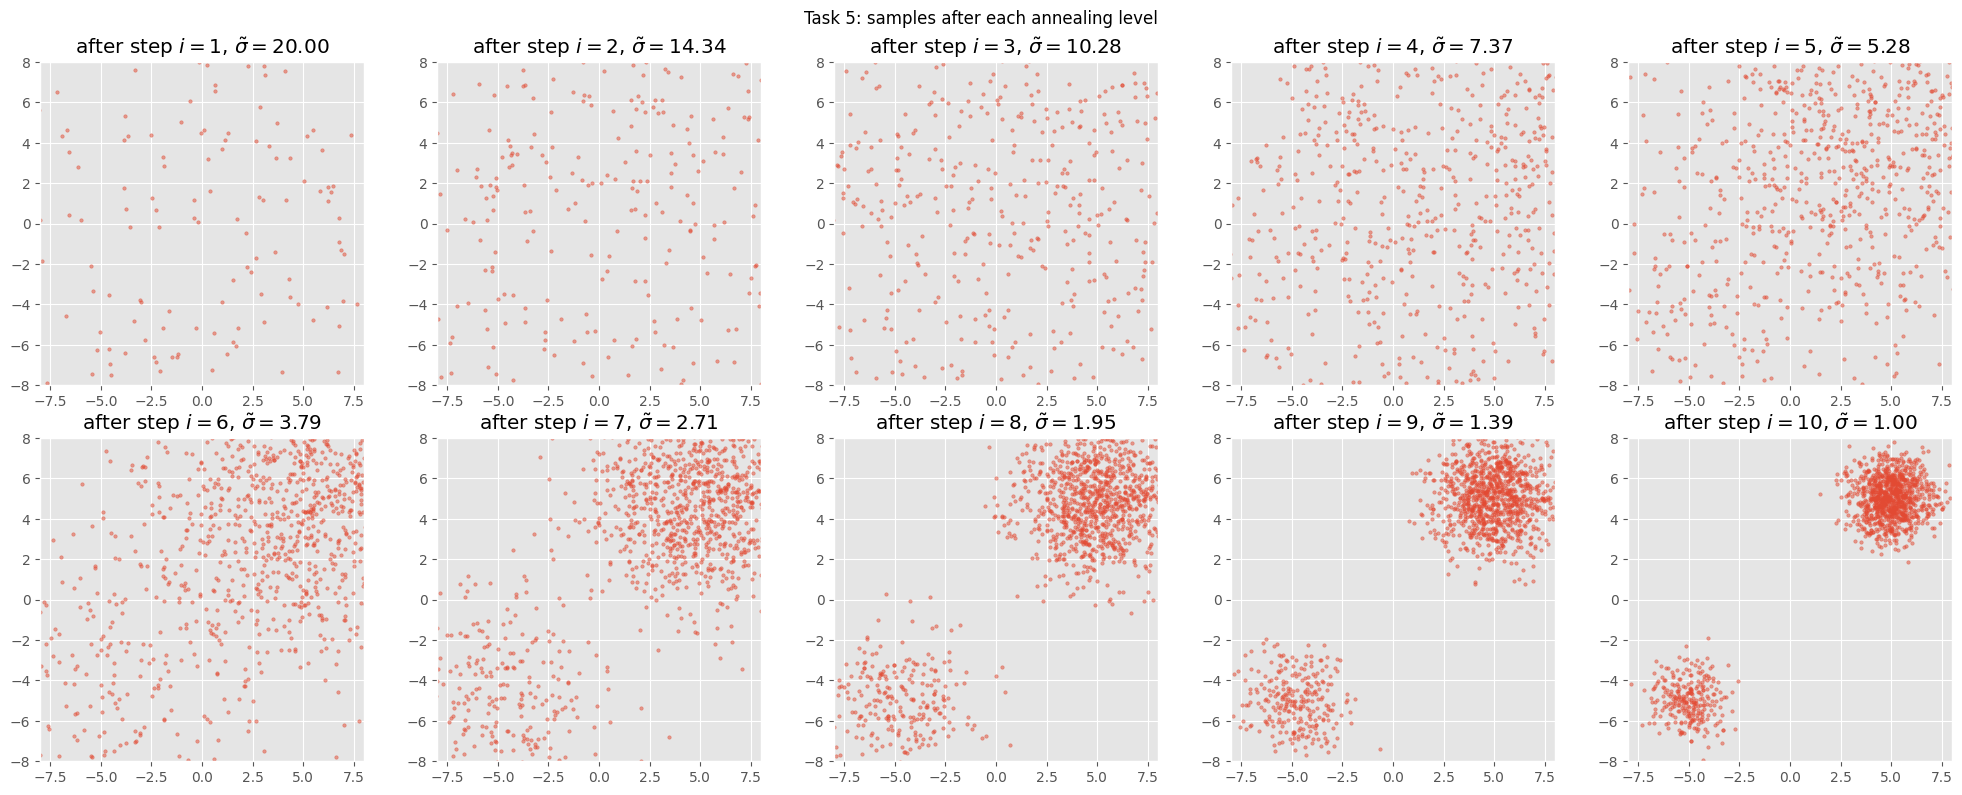

In [8]:
# Task 5 — annealed Langevin dynamics
def annealed_langevin(score, init, sigmas, epsilon, T):
    """Annealed Langevin dynamics. score(x, sigma=...) -> (n, 2)."""
    x = init.clone()
    sigma_L = float(sigmas[-1])
    snapshots = []
    for sigma_i in sigmas:
        sigma_i = float(sigma_i)
        eps_i = epsilon * (sigma_i ** 2) / (sigma_L ** 2)
        sqrt_2eps_i = float(np.sqrt(2 * eps_i))
        for _ in range(T):
            z = torch.randn_like(x)
            x = x + eps_i * score(x, sigma=sigma_i) + sqrt_2eps_i * z
        snapshots.append(x.clone())
    return x, snapshots

torch.manual_seed(0)
sigmas_t5 = np.exp(np.linspace(np.log(20.), np.log(1.), 10))   # tilde-sigma_1 ... tilde-sigma_L
n = 1280
init_uniform = torch.rand(n, 2) * 16 - 8
samples_t5, snapshots_t5 = annealed_langevin(gmm.score, init_uniform, sigmas_t5, epsilon=0.05, T=100)

plt.figure(figsize=(6, 6))
plt.scatter(samples_t5[:, 0].numpy(), samples_t5[:, 1].numpy(), s=8, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8); plt.gca().set_aspect('equal')
plt.title(r'Task 5: annealed Langevin samples ($\epsilon=0.05, T=100$, $L=10$)')
plt.show()

w_small_t5 = ((samples_t5[:, 0] < 0) & (samples_t5[:, 1] < 0)).float().mean().item()
print(f'Task 5: empirical weight on small mode = {w_small_t5:.3f} (true value: 0.20)')

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in enumerate(axes.flat):
    snap = snapshots_t5[i]
    ax.scatter(snap[:, 0].numpy(), snap[:, 1].numpy(), s=6, alpha=0.5)
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect('equal')
    ax.set_title(rf'after step $i={i+1}$, $\tilde\sigma={sigmas_t5[i]:.2f}$')
fig.suptitle('Task 5: samples after each annealing level')
plt.tight_layout(); plt.show()


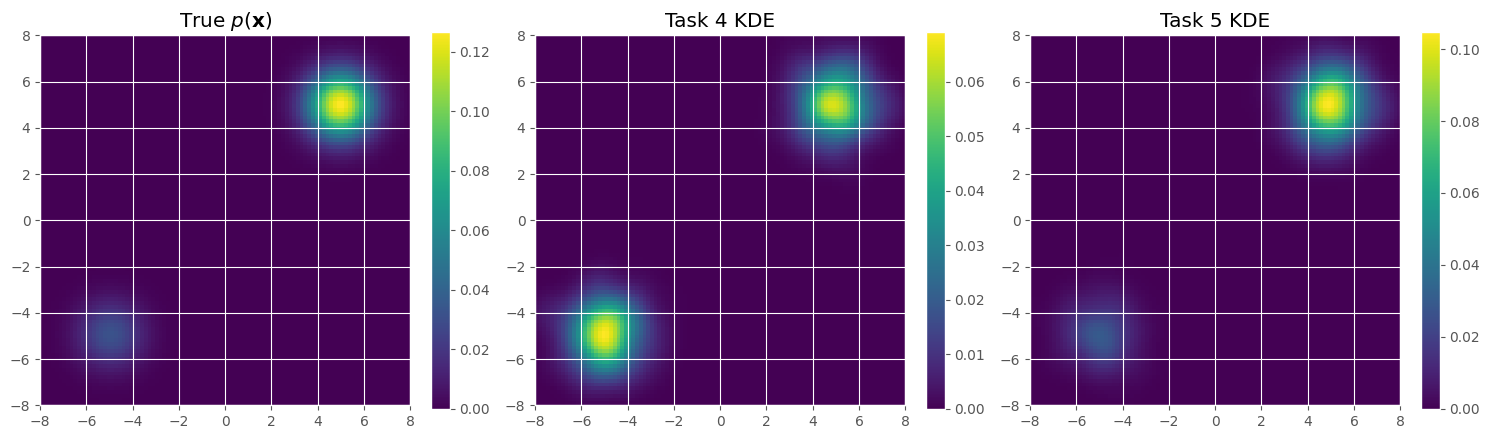

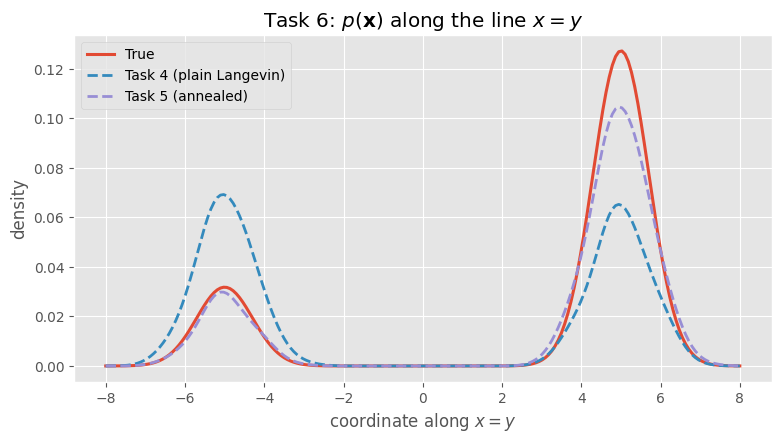

In [9]:
# Task 6 — KDE comparison vs true density
from sklearn.neighbors import KernelDensity

def kde_density(samples_tensor, eval_pts_tensor, bandwidth=0.5):
    kde = KernelDensity(bandwidth=bandwidth)
    kde.fit(samples_tensor.detach().cpu().numpy())
    return np.exp(kde.score_samples(eval_pts_tensor.detach().cpu().numpy()))

# 2D comparison (100 x 100 grid)
true_p_2d = torch.exp(gmm.log_prob(grid100)).reshape(100, 100).numpy()
p_t4_2d   = kde_density(samples_t4, grid100).reshape(100, 100)
p_t5_2d   = kde_density(samples_t5, grid100).reshape(100, 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, dat, title in zip(axes,
                          [true_p_2d, p_t4_2d, p_t5_2d],
                          [r'True $p(\mathbf{x})$', 'Task 4 KDE', 'Task 5 KDE']):
    im = ax.imshow(dat.T, origin='lower', extent=[-8, 8, -8, 8], cmap='viridis')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# 1D slice along x = y
diag = torch.linspace(-8, 8, 200)
diag_pts = torch.stack([diag, diag], dim=1)
true_diag = torch.exp(gmm.log_prob(diag_pts)).squeeze(-1).numpy()
t4_diag = kde_density(samples_t4, diag_pts)
t5_diag = kde_density(samples_t5, diag_pts)

plt.figure(figsize=(9, 4.5))
plt.plot(diag.numpy(), true_diag, label='True', lw=2.2)
plt.plot(diag.numpy(), t4_diag,   label='Task 4 (plain Langevin)', ls='--')
plt.plot(diag.numpy(), t5_diag,   label='Task 5 (annealed)',       ls='--')
plt.xlabel(r'coordinate along $x = y$'); plt.ylabel('density')
plt.title(r'Task 6: $p(\mathbf{x})$ along the line $x = y$')
plt.legend(); plt.show()


## Part II: Score Matching (60 points)

So far, we assumed we have access to the underlying ground truth scores. However, in reality we only have access to $i.i.d.$ samples $\mathbf{x}_i\sim p\left(\mathbf{x}\right)$ from which we need to learn these scores. To learn the scores, we would like to minimize the Fisher Divergence between the score model $s_{\theta}\left(\mathbf{x}\right)$ and the true data scores $\nabla_{\mathbf{x}}\log p\left(\mathbf{x}\right)$:
$$\frac{1}{2}\mathbb{E}_{p\left(\mathbf{x}\right)}\left[\|s_{\theta}\left(\mathbf{x}\right)-\nabla_{\mathbf{x}}\log p\left(\mathbf{x}\right)\|_2^2\right]$$
However, we don't know the ground truth scores $\nabla_{\mathbf{x}}\log p\left(\mathbf{x}\right)$, and therefore we can't compute the Fisher Divergence directly. Luckily, this objective can be shown equivalent to the following up to a constant:
$$\mathbb{E}_{p\left(\mathbf{x}\right)}\left[\mathrm{tr}\left(\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\right)+\frac{1}{2}\|s_{\theta}\left(\mathbf{x}\right)\|_2^2\right]$$
where $\mathrm{tr}\left(\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\right)$ is the trace of the Jacobian of $s_{\theta}\left(\mathbf{x}\right)$. In deep networks calculating the trace of the Jacobian is very expensive computationally, and therefore there are two popular methods to circumvent its calculation. In class we saw one method for avoiding the costly Jacobian computation, called Denoising Score Matching (DSM). DSM is a variant of score matching that completely circumvents $\mathrm{tr}\left(\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\right)$. It first perturbs the data point $\mathbf{x}$ with a pre-specified noise distribution $q_{\sigma}\left(\tilde{\mathbf{x}}\lvert \mathbf{x}\right)$ and then employs score matching to estimate the score of the perturbed data distribution $q_{\sigma}(\tilde{\mathbf{x}}) \triangleq \int p(\mathbf{x}) \mathcal{N}(\tilde{\mathbf{x}}|\mathbf{x},\sigma^2 I)d\mathbf{x}$. The DSM objective was proved equivalent to the following:
$$\mathbb{E}_{q_{\sigma}\left(\tilde{\mathbf{x}}\lvert \mathbf{x}\right) p\left(\mathbf{x}\right)}\left[\|s_{\theta}\left(\tilde{\mathbf{x}}\right)-\nabla_{\tilde{\mathbf{x}}}\log q_{\sigma}\left(\tilde{\mathbf{x}}\lvert \mathbf{x}\right)\|_2^2\right],$$
where the optimal minimizer satisfies $s_{\theta^{\star}}\left(\tilde{\mathbf{x}}\right)=\nabla_{\tilde{\mathbf{x}}}\log q_{\sigma}\left(\tilde{\mathbf{x}}\right) \approx \nabla_{\mathbf{x}}\log p\left(\mathbf{x}\right)$, which is roughly true when the noise is small enough such that $q_{\sigma}\left(\tilde{\mathbf{x}}\right) \approx p\left(\mathbf{x}\right)$.

Here we will see a different method, called Sliced Score Matching (SSM). SSM uses random projections to approximate $\mathrm{tr}\left(\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\right)$. The objective is given by:
$$ \mathbb{E}_{p\left(\mathbf{x}\right)}\left[\mathbb{E}_{p\left(\mathbf{v}\right)} \left[\mathbf{v}^T\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\mathbf{v} + \frac{1}{2}\|s_{\theta}\left(\mathbf{x}\right)\|_2^2\right]\right]$$
where $p_{\mathbf{v}}$ is a simple distribution of random vectors, e.g. the multivariate standard normal. Note that the term $\mathbf{v}^T\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\mathbf{v}$ can be efficiently computed by forward mode auto-differentiation. Meaning, assuming we have a random vector `v`, and a score model `score` that accepts `x` as input and outputs the score `s_x` as output, we can compute the term $\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\mathbf{v}$ using:
```
x.requires_grad_(True)
s_x = score(x)
grad_sx_v = autograd.grad(torch.sum(s_x*v), x, create_graph=True)[0]
```
<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 7</span>**. Implement a function that calculates the sliced score matching objective. Your function should accept three inputs:
 * `score_net` - the score model that accepts samples and estimate the scores.
 * `samples` - the current batch of $B \times 2$ training samples $\mathbf{x}_i$.
 * `nv` - the number of random vectors to approximate $\mathbb{E}_{p\left(\mathbf{v}\right)}$ using samples.

Tip: to enable forward mode auto-differentiation of the score model `score_net` w.r.t. the input samples `samples`, you need to set their `.requires_grad_()` property to `True`.

In [10]:
def sliced_score_matching(score_net, samples, nv=1):
    """Sliced Score Matching objective (random-projection trace estimator)."""
    samples = samples.detach()
    samples.requires_grad_(True)
    s = score_net(samples)                                      # (B, 2)

    # 0.5 * ||s(x)||^2 term
    loss_norm = 0.5 * (s ** 2).sum(dim=-1)                      # (B,)

    # Stochastic trace term: v^T (ds/dx) v, averaged over nv random v's
    loss_trace = 0.
    for _ in range(nv):
        v = torch.randn_like(samples)
        sv = (s * v).sum()
        grad_sv = autograd.grad(sv, samples, create_graph=True)[0]
        loss_trace = loss_trace + (grad_sv * v).sum(dim=-1)
    loss_trace = loss_trace / nv

    return (loss_trace + loss_norm).mean()


Now that we have an objective quantifying how good we can estimate the underlying scores, we can train a neural network. For the purpose of this exercise we will use a simple 3-layer fully connected network with the smooth "Softplus" activation function:

In [11]:
score_net = nn.Sequential(nn.Linear(2, 128),
                          nn.Softplus(),
                          nn.Linear(128, 128),
                          nn.Softplus(),
                          nn.Linear(128, 2))

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 8</span>**. Train a score model using the following training function with the default arguments:

In [12]:
# training function: model, optimizer and loss
def train(score_net, batch_size=128, nsteps=10000, lr=0.001):

    # initialize the sampler, the optimizer and the loss list
    teacher = GMMDist()
    optimizer = optim.Adam(score_net.parameters(), lr=lr)
    losses = []

    # train until stagnation (can't overfit due to infinite data)
    tqdm_steps = tqdm.trange(nsteps)
    for step in tqdm_steps:

        # sample x_i~p(x) and calculate the slice-score-matching objective
        samples = teacher.sample(batch_size)
        loss = sliced_score_matching(score_net, samples, nv=1)

        # backprop to update the score model
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # print and save current loss
        losses.append(loss.detach().item())
        if step % 50 == 0:
            tqdm_steps.set_description('step: {}, loss: {:.5f}'.format(step, loss.item()))

    return losses, score_net

This function internally uses the class method `GMMDist.sample` from Task 1 as an infinite data sampler, and calculates the sliced score matching objective using the implemented function from Task 7. After training is done, the function outputs the loss progression during training `losses` and the optimized score model `score_net`. Plot the resulting loss curve for the first 1000 steps for sanity check. After training is done, use the resulting score model `score_net` to estimate the scores at a 2D grid of $20\times 20$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$. Plot the estimated scores as a vector field using a [quiver plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.quiver.html), and compare the result to the real data scores from Task 3. Are the estimated scores uniformly accurate across the considered domain? If not, point out the most accurate areas, and explain the result.

  0%|          | 0/10000 [00:00<?, ?it/s]

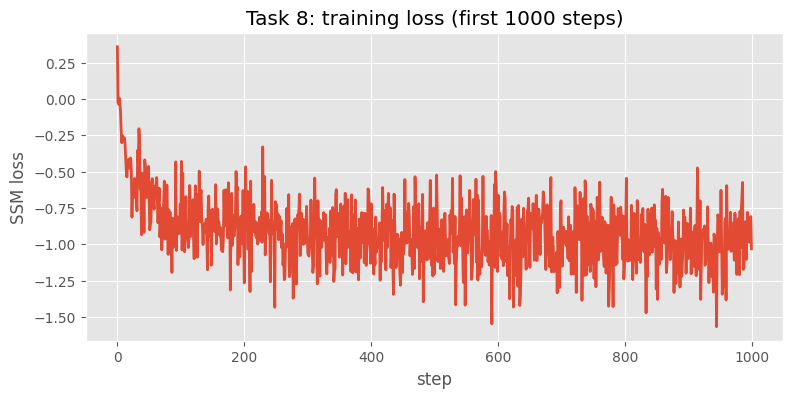

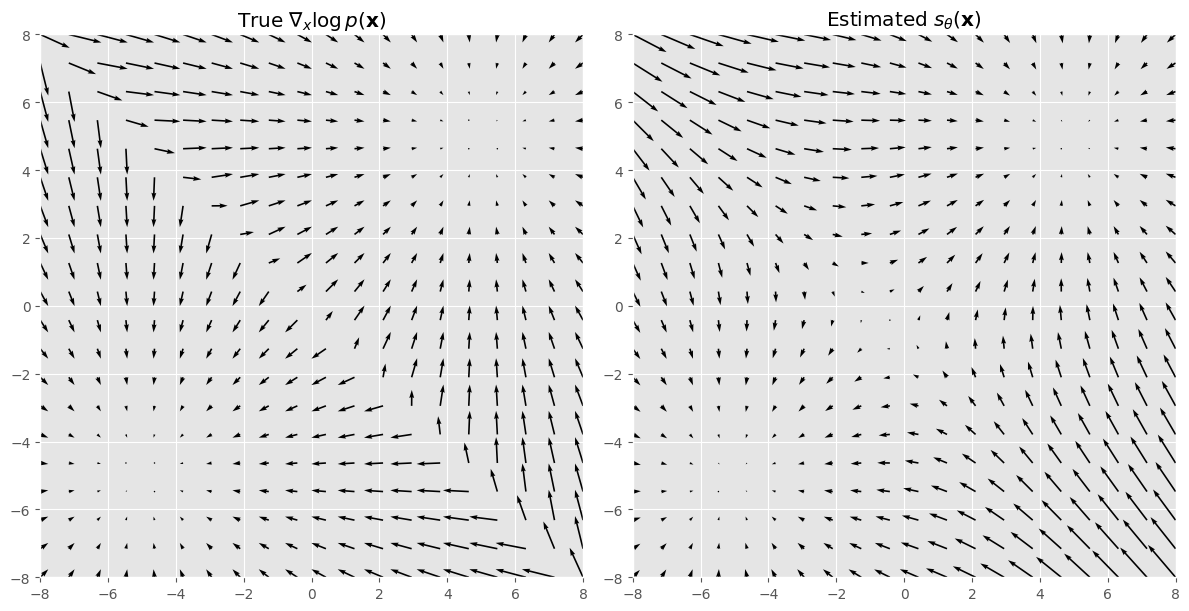

In [13]:
# Task 8 — train SSM model and plot estimated score field
torch.manual_seed(0)
losses_t8, score_net = train(score_net)

plt.figure(figsize=(9, 4))
plt.plot(losses_t8[:1000])
plt.xlabel('step'); plt.ylabel('SSM loss')
plt.title('Task 8: training loss (first 1000 steps)')
plt.show()

with torch.no_grad():
    est_scores_t8 = score_net(grid20)
true_scores_t8 = gmm.score(grid20)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, sc, title in zip(axes,
                         [true_scores_t8, est_scores_t8],
                         [r'True $\nabla_x \log p(\mathbf{x})$',
                          r'Estimated $s_\theta(\mathbf{x})$']):
    ax.quiver(X20.numpy(), Y20.numpy(),
              sc[:, 0].reshape(20, 20).numpy(),
              sc[:, 1].reshape(20, 20).numpy())
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect('equal')
    ax.set_title(title)
plt.tight_layout(); plt.show()


<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 9</span>**. Now that we have a trained model estimating the score, we can sample data samples from $p(x)$ using Langevin dynamics as we did in Task 4. Repeat Task 4 with the estimated score model from Task 8, and plot the resulting samples. Compare the samples obtained using the estimated vs the real scores. In addition, compare the estimated probability distribution $\hat{p}\left(\mathbf{x}\right)$ at a 2D grid of $100\times 100$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$ with the result of Task 2. To estimate $\hat{p}\left(\mathbf{x}\right)$ of the score model use kernel density estimation implemented with `sklearn.neighbors.KernelDensity()` with `bandwidth=0.5` on the samples from Langevin dynamics. Discuss the results.

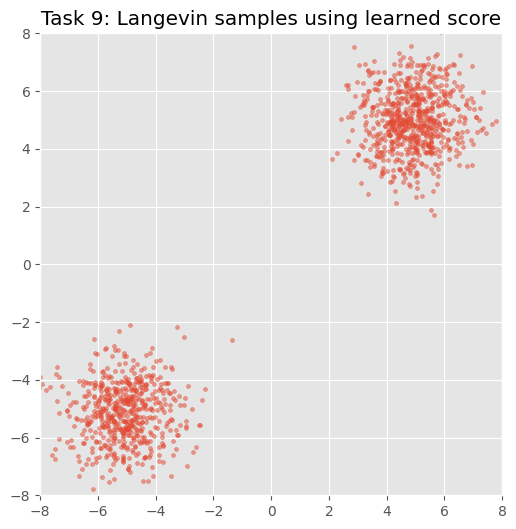

Task 9: empirical weight on small mode = 0.449 (true value: 0.20)


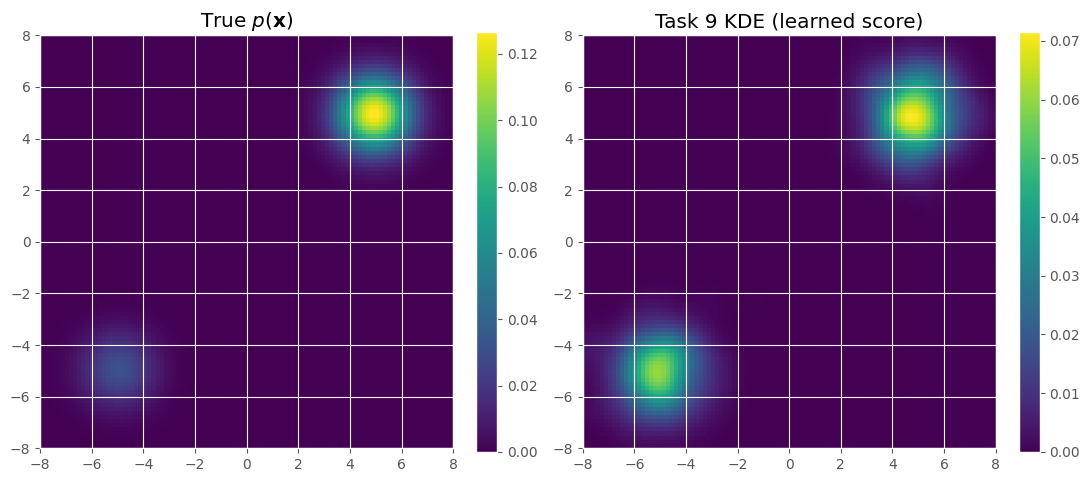

In [14]:
# Task 9 — Langevin with the learned score
def est_score_t9(x, sigma=1):
    with torch.no_grad():
        return score_net(x)

torch.manual_seed(0)
init_uniform = torch.rand(1280, 2) * 16 - 8
samples_t9 = langevin_dynamics(est_score_t9, init_uniform, epsilon=0.05, T=1000)

plt.figure(figsize=(6, 6))
plt.scatter(samples_t9[:, 0].numpy(), samples_t9[:, 1].numpy(), s=8, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8); plt.gca().set_aspect('equal')
plt.title('Task 9: Langevin samples using learned score')
plt.show()

w_small_t9 = ((samples_t9[:, 0] < 0) & (samples_t9[:, 1] < 0)).float().mean().item()
print(f'Task 9: empirical weight on small mode = {w_small_t9:.3f} (true value: 0.20)')

p_t9_2d = kde_density(samples_t9, grid100).reshape(100, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, dat, title in zip(axes,
                          [true_p_2d, p_t9_2d],
                          [r'True $p(\mathbf{x})$', 'Task 9 KDE (learned score)']):
    im = ax.imshow(dat.T, origin='lower', extent=[-8, 8, -8, 8], cmap='viridis')
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()


As we saw earlier in Task 5, even with the perfect scores Langevin dynamics can have practical pitfalls when sampling our Toy distribution. One solution in such cases is using **annealing** with multiple standard deviations $\{\sigma_i\}_{i=1}^L$ to improve the results. However, that requires us to know the scores of all $L$ distributions $q_{\sigma_i}(\tilde{\mathbf{x}}) = \int p(\mathbf{x}) \mathcal{N}(\tilde{\mathbf{x}}|\mathbf{x},\sigma_i^2 I)d\mathbf{x}$. While in theory we can learn $L$ separate score models to approximate the desired sequence of scores $\nabla_{\tilde{\mathbf{x}}}\log q_{\sigma_i}(\tilde{\mathbf{x}})$, in practice this is too heavy and computationally inefficient. Therefore, to alleviate this issue, we can learn a single score model that is conditioned on the standard deviation $\sigma_i^2$ of the added noise to our samples, i.e. $s_{\theta}\left(\mathbf{x},\sigma_i^2\right)$. As noted in [this paper](https://arxiv.org/abs/2006.09011), a simple reparameterization of the conditional score model $s_{\theta}\left(\mathbf{x},\sigma_i^2\right)$ into $\frac{s_{\theta}\left(\mathbf{x}\right)}{\sigma_i}$ could suffice in practice. However, we still need to train this model with $L$ noisy versions of our dataset $\{\tilde{\mathbf{x}}_j\}_i$, where the samples in the $i^{\text{th}}$ dataset are simulated according to $\tilde{\mathbf{x}}_j \sim \mathcal{N}\left(\tilde{\mathbf{x}}_j;\mathbf{x}_j,\sigma_i^2\right)$. This can be achieved by replacing our sliced score matching objective from Task 7 with an annealed version like so:
$$\mathcal{L}\left(\theta;\{\sigma_i\}_{i=1}^L\right) = \frac{1}{L} \sum_{i=1}^L { \lambda\left(\sigma_i\right) \ell\left(\theta;\sigma_i\right)}, $$
where $\lambda\left(\sigma_i\right) > 0$ is a coefficient function depending on $\sigma_i$, and $\ell\left(\theta;\sigma_i\right) = \mathbb{E}_{p\left(\mathbf{x}\right)}\left[\mathbb{E}_{p\left(\mathbf{v}\right)} \left[\mathbf{v}^T\nabla_{\mathbf{x}}s_{\theta}\left(\mathbf{x}\right)\mathbf{v} + \frac{1}{2}\|s_{\theta}\left(\mathbf{x}\right)\|_2^2\right]\right]$ is the sliced score matching objective from Task 7. Specifically, in our implementation we will use $\lambda\left(\sigma\right) = \sigma^2$ which was shown to be a good choice to make the values of $\lambda\left(\sigma_i\right)\ell\left(\theta;\sigma_i\right)$ for all $\{\sigma_i\}_{i=1}^L$ roughly of the same order.

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 10</span>**. Implement the **Annealed** version of the sliced score matching objective. Your function should accept four inputs:
 * `cond_score_net` - the conditional score model that accepts `samples` and `used_sigmas`, and estimate the `scores`.
 * `perturbed_samples` - the current batch of $B \times 2$ perturbed training samples $\tilde{\mathbf{x}}_i$.
 * `used_sigmas` - $B \times 1$ vector indicating the used standard deviation `sigma` corresponding to each sample in the batch.
 * `nv` - the number of random vectors to approximate $\mathbb{E}_{p\left(\mathbf{v}\right)}$ using samples.

In [15]:
def annealed_sliced_score_matching(cond_score_net, perturbed_samples, used_sigmas, nv=1):
    """Annealed SSM: per-sample lambda(sigma)=sigma^2 weighted SSM."""
    perturbed_samples = perturbed_samples.detach()
    perturbed_samples.requires_grad_(True)
    s = cond_score_net(perturbed_samples, used_sigmas)          # (B, 2)

    # 0.5 * ||s(x_tilde)||^2 term
    loss_norm = 0.5 * (s ** 2).sum(dim=-1, keepdim=True)        # (B, 1)

    # Stochastic trace term
    loss_trace = 0.
    for _ in range(nv):
        v = torch.randn_like(perturbed_samples)
        sv = (s * v).sum()
        grad_sv = autograd.grad(sv, perturbed_samples, create_graph=True)[0]
        loss_trace = loss_trace + (grad_sv * v).sum(dim=-1, keepdim=True)
    loss_trace = loss_trace / nv                                # (B, 1)

    # lambda(sigma) = sigma^2 weighting per-sample, then average
    loss = (used_sigmas ** 2) * (loss_trace + loss_norm)        # (B, 1)
    return loss.mean()


Now that we have an annealed version of our sliced score matching objective, we can train a **noise-conditional** score model to estimate the desired sequence of scores $\{\nabla_{\tilde{\mathbf{x}}}\log q_{\sigma_i}(\tilde{\mathbf{x}})\}_{i=1}^L$. For the purpose of this excercise, we will use the following simple conditional score model (both taking $\sigma_i$ as input and normalizing the output):

In [16]:
# simple conditional score model
class CondScoreNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.cond_score_net = nn.Sequential(nn.Linear(3, 128),
                                            nn.Softplus(),
                                            nn.Linear(128, 128),
                                            nn.Softplus(),
                                            nn.Linear(128, 2))

    def forward(self, x, used_sigmas):
        x = torch.cat((x, used_sigmas), axis=1)
        return self.cond_score_net(x)/used_sigmas
cond_score_net = CondScoreNet()

<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 11</span>**. Train a **noise-conditional** score model using the following training function with the default arguments:

In [17]:
# training function: model, optimizer and loss
def train_annealed(cond_score_net, sigmas, batch_size=256, nsteps=10000, lr=0.001):

    # initialize the sampler, the optimizer and the loss list
    teacher = GMMDist()
    optimizer = optim.Adam(cond_score_net.parameters(), lr=lr)
    losses = []

    # train until stagnation (can't overfit due to infinite data)
    tqdm_steps = tqdm.trange(nsteps)
    for step in tqdm_steps:

        # sample x_i~p(x)
        samples = teacher.sample(batch_size)

        # sample noise stds and perturb the samples accorindgly
        labels = torch.randint(0, len(sigmas), (batch_size,))
        used_sigmas = sigmas[labels].view(samples.shape[0], 1)
        perturbed_samples = samples + torch.randn_like(samples) * used_sigmas

        # calculate the annealed slice-score-matching objective
        loss = annealed_sliced_score_matching(cond_score_net, perturbed_samples, used_sigmas, nv=1)

        # backprop to update the score model
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # print and save current loss
        losses.append(loss.detach().item())
        if step % 50 == 0:
            tqdm_steps.set_description('step: {}, loss: {:.5f}'.format(step, loss.item()))

    return losses, cond_score_net

Use `sigmas=np.exp(np.linspace(np.log(10.),np.log(.1),10))` for the sequence of $L=10$ standard deviations $\{\sigma_i\}_{i=1}^L$. After training is done, the function outputs the loss progression during training `losses` and the optimized noise-conditional score model `cond_score_net`. Plot the resulting loss curve for the first 1000 steps for sanity check. Use the resulting score model `cond_score_net` to estimate the scores at a 2D grid of $20\times 20$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$ for all noise levels. Plot the estimated scores as a vector field using a [quiver plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.quiver.html) (each in a separate plot), and discuss the extreme cases: $\sigma_L$ and $\sigma_1$ vs the real data scores from Task 3 with an equivalent standard deviation (i.e. $\tilde{\sigma}_i = \sqrt{\sigma_i^2 + \sigma^2}$). To guide your intuition, plot the respective $ p\left(\mathbf{x};\tilde{\sigma}_i\right)$ at a 2D grid of $100\times 100$ points in the domain $\left[-8,8\right]\times\left[-8,8\right]$ using the method from Task 2.

  0%|          | 0/10000 [00:00<?, ?it/s]

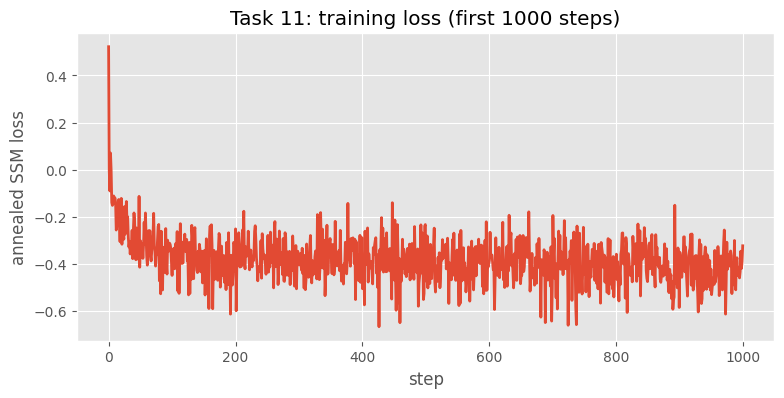

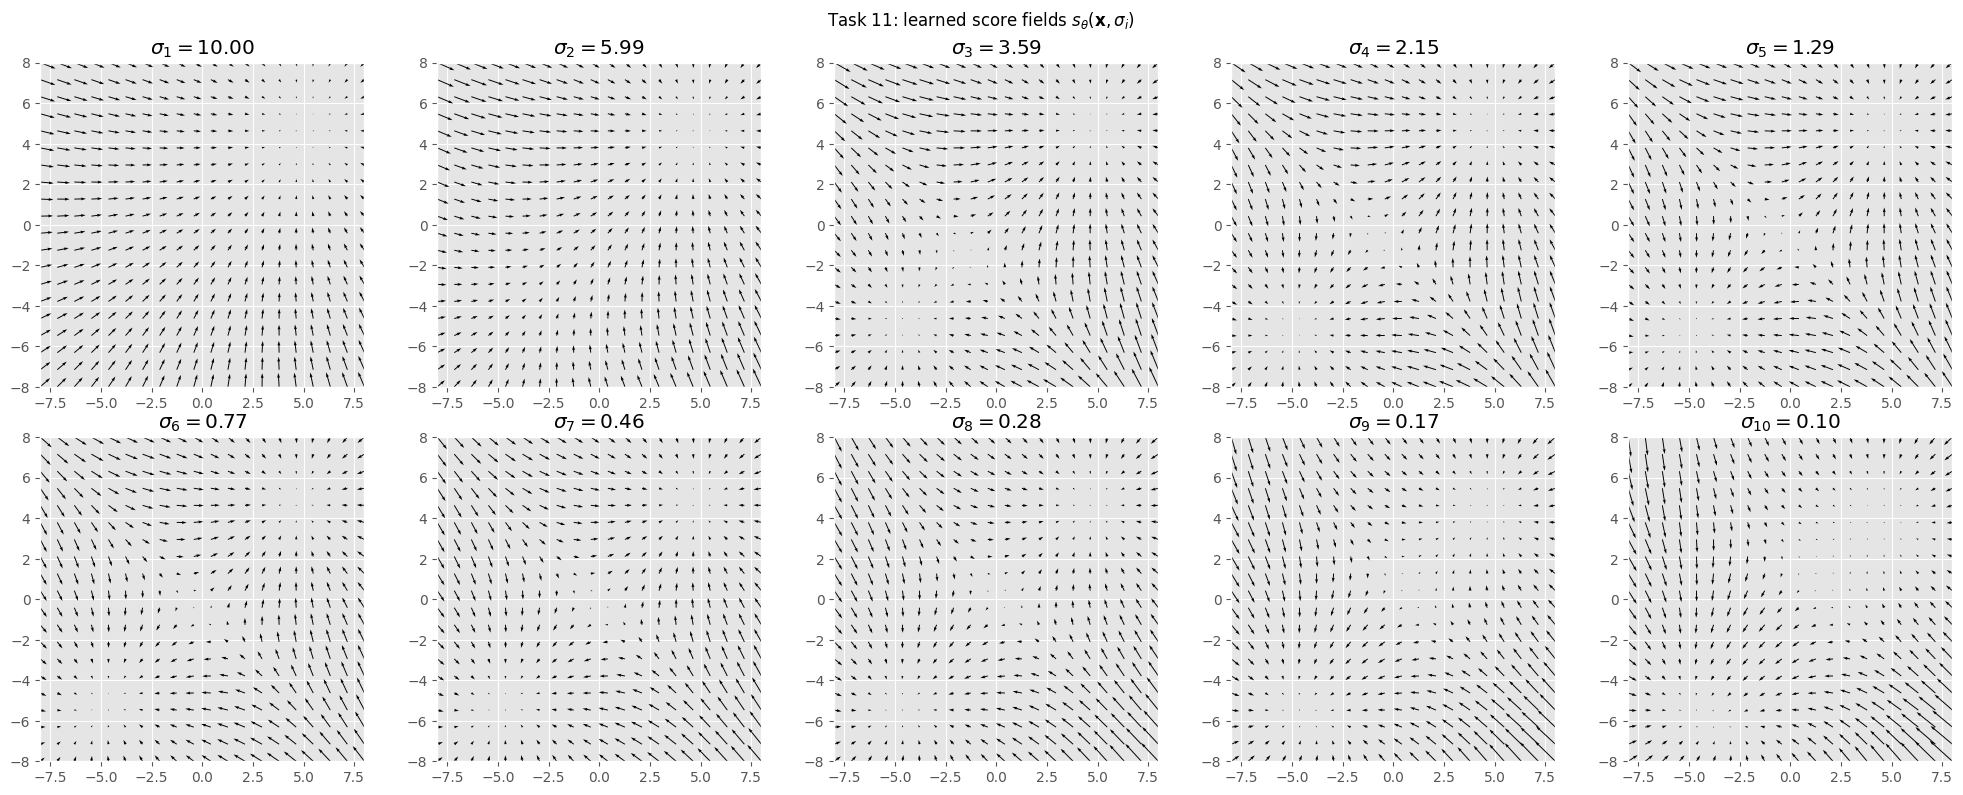

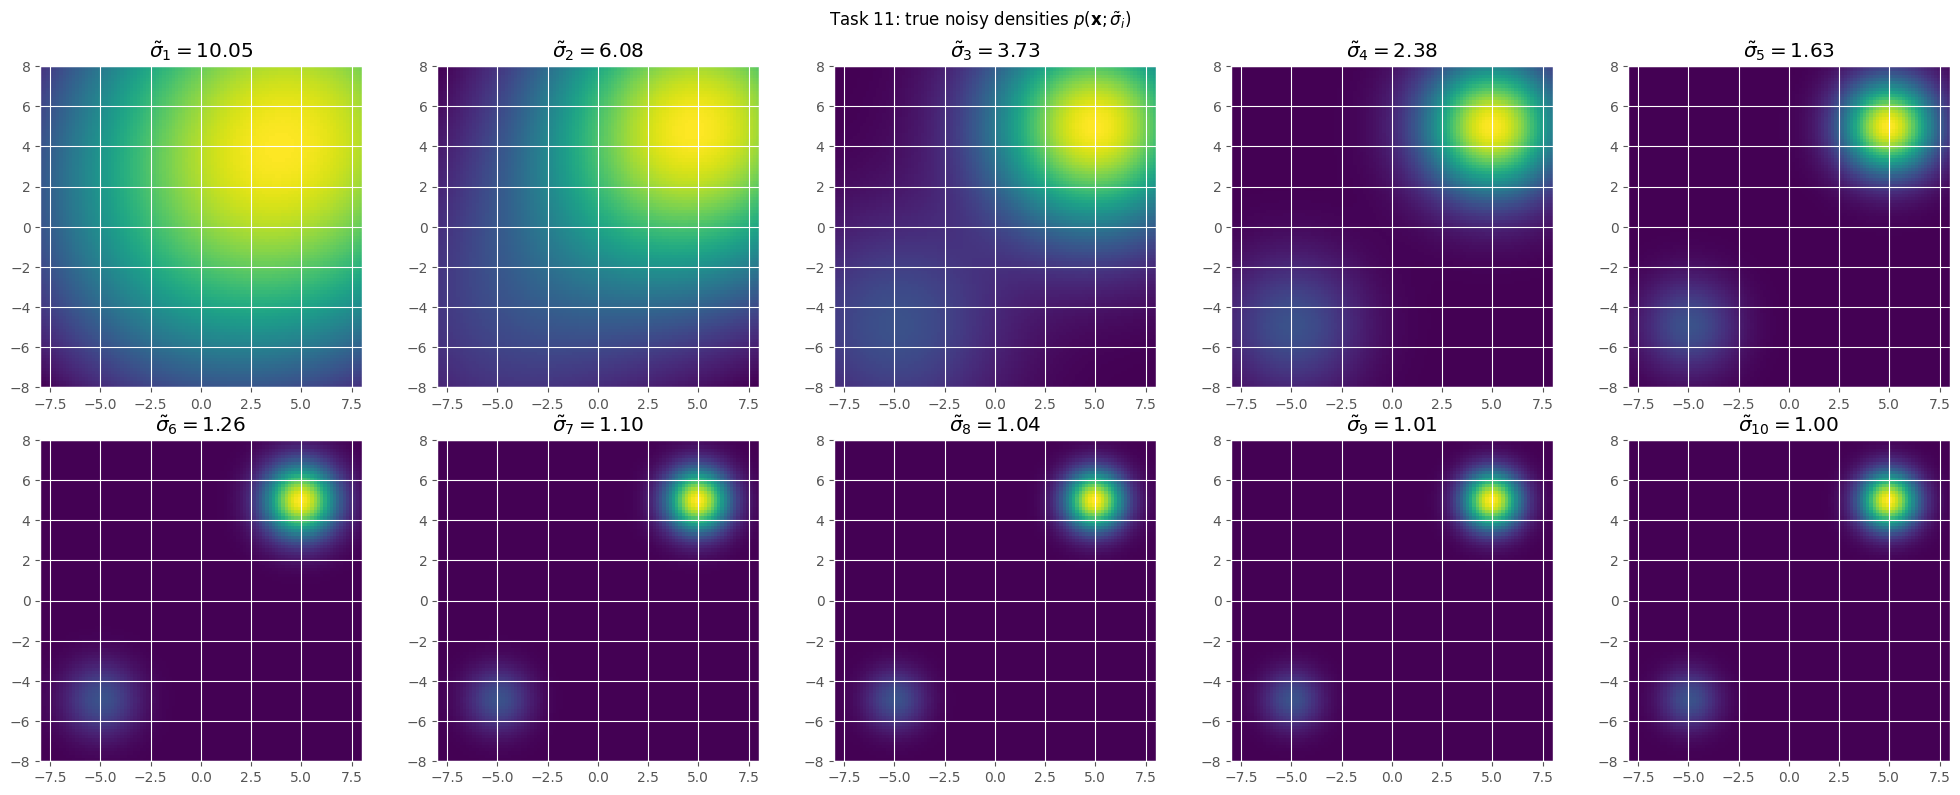

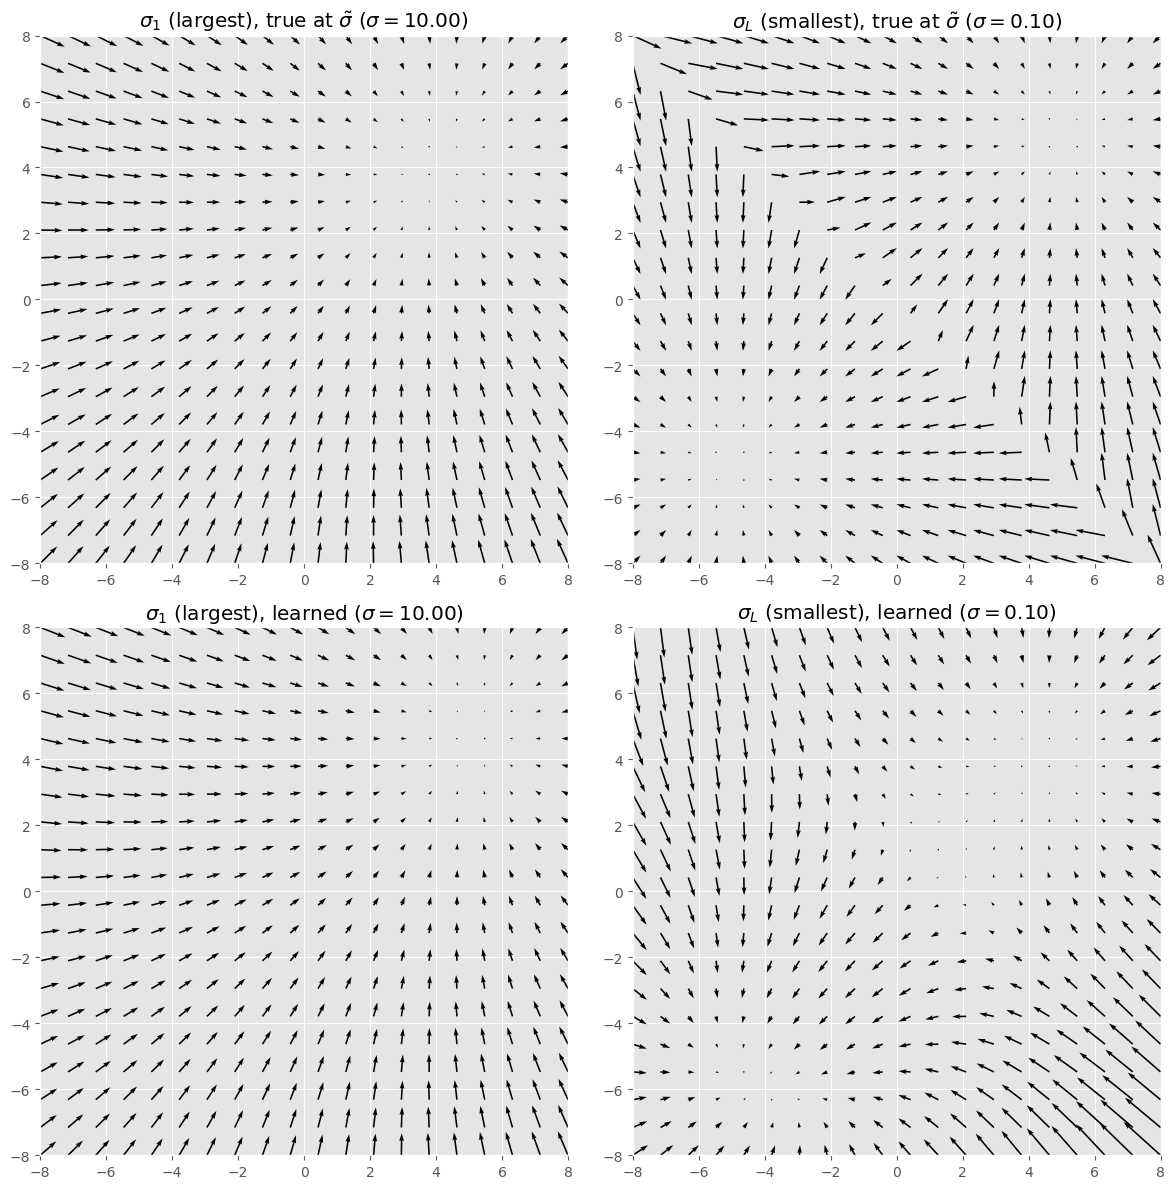

In [18]:
# Task 11 — train noise-conditional score model
sigmas_t11 = torch.tensor(np.exp(np.linspace(np.log(10.), np.log(.1), 10)), dtype=torch.float32)
torch.manual_seed(0)
losses_t11, cond_score_net = train_annealed(cond_score_net, sigmas_t11)

plt.figure(figsize=(9, 4))
plt.plot(losses_t11[:1000])
plt.xlabel('step'); plt.ylabel('annealed SSM loss')
plt.title('Task 11: training loss (first 1000 steps)')
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in enumerate(axes.flat):
    sigma_i = float(sigmas_t11[i])
    used = torch.full((grid20.shape[0], 1), sigma_i)
    with torch.no_grad():
        sc = cond_score_net(grid20, used)
    ax.quiver(X20.numpy(), Y20.numpy(),
              sc[:, 0].reshape(20, 20).numpy(),
              sc[:, 1].reshape(20, 20).numpy())
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect('equal')
    ax.set_title(rf'$\sigma_{{{i+1}}}={sigma_i:.2f}$')
fig.suptitle(r'Task 11: learned score fields $s_\theta(\mathbf{x}, \sigma_i)$')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in enumerate(axes.flat):
    eff_sigma = float(np.sqrt(sigmas_t11[i].item() ** 2 + 1.0))
    p_eff = torch.exp(gmm.log_prob(grid100, sigma=eff_sigma)).reshape(100, 100).numpy()
    ax.imshow(p_eff.T, origin='lower', extent=[-8, 8, -8, 8], cmap='viridis')
    ax.set_title(rf'$\tilde\sigma_{{{i+1}}}={eff_sigma:.2f}$')
fig.suptitle(r'Task 11: true noisy densities $p(\mathbf{x}; \tilde\sigma_i)$')
plt.tight_layout(); plt.show()

# Extreme cases vs true scores
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for col, idx, label in [(0, 0, r'$\sigma_1$ (largest)'),
                        (1, -1, r'$\sigma_L$ (smallest)')]:
    sigma_i = float(sigmas_t11[idx])
    eff_sigma = float(np.sqrt(sigma_i ** 2 + 1.0))
    used = torch.full((grid20.shape[0], 1), sigma_i)
    with torch.no_grad():
        sc_learned = cond_score_net(grid20, used)
    sc_true = gmm.score(grid20, sigma=eff_sigma)
    for row, sc, src in [(0, sc_true, r'true at $\tilde\sigma$'),
                         (1, sc_learned, 'learned')]:
        ax = axes[row, col]
        ax.quiver(X20.numpy(), Y20.numpy(),
                  sc[:, 0].reshape(20, 20).numpy(),
                  sc[:, 1].reshape(20, 20).numpy())
        ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect('equal')
        ax.set_title(rf'{label}, {src} ($\sigma={sigma_i:.2f}$)')
plt.tight_layout(); plt.show()


<img src="https://img.icons8.com/offices/80/000000/making-notes.png" style="height:30px;display:inline\">**<span style="color:red">Task 12</span>**. Now that we have a noise-conditional score model approximating the sequence of scores $\{\nabla_{\tilde{\mathbf{x}}}\log q_{\sigma_i}(\tilde{\mathbf{x}})\}_{i=1}^L$ we can use the **Annealed** version of Langevin dynamics to produce samples from $p\left(\mathbf{x}\right)$. Repeat Task 5 using the estimated model from Task 11. Show the resulting samples for $n=1280, \epsilon=0.0005, T=100$. Discuss the results in terms of the relative mode weight compared to Task 9. Plot the resulting samples for each annealing step $i=1,\dots,L$ (you're encouraged to create an animation), and explain the effect of using multiple standard deviations.

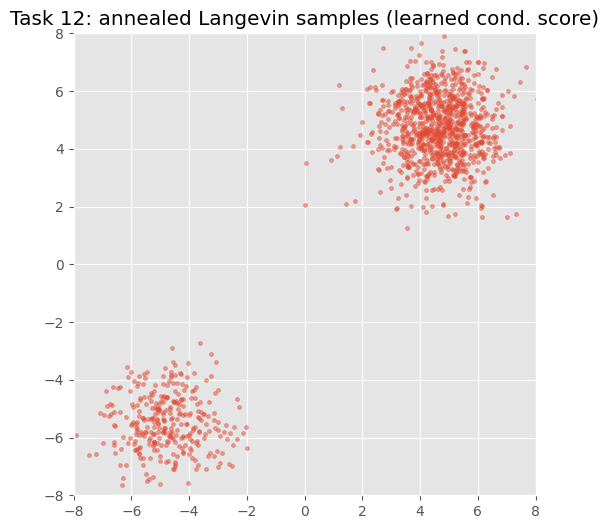

Task 12: empirical weight on small mode = 0.245 (true value: 0.20)


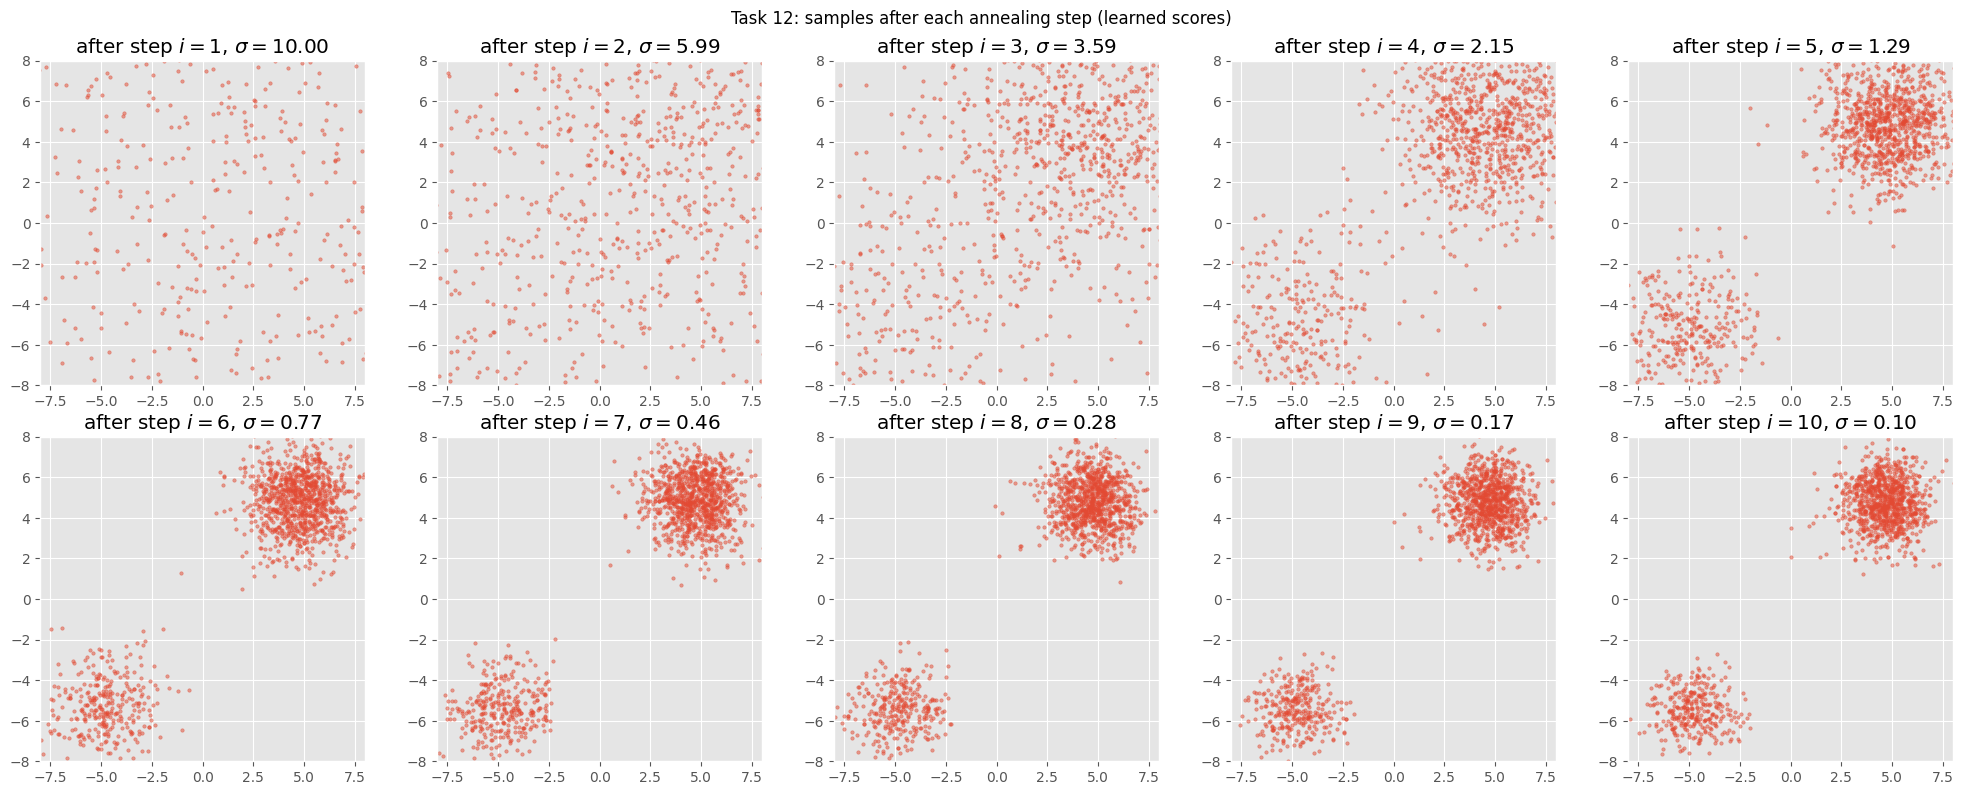

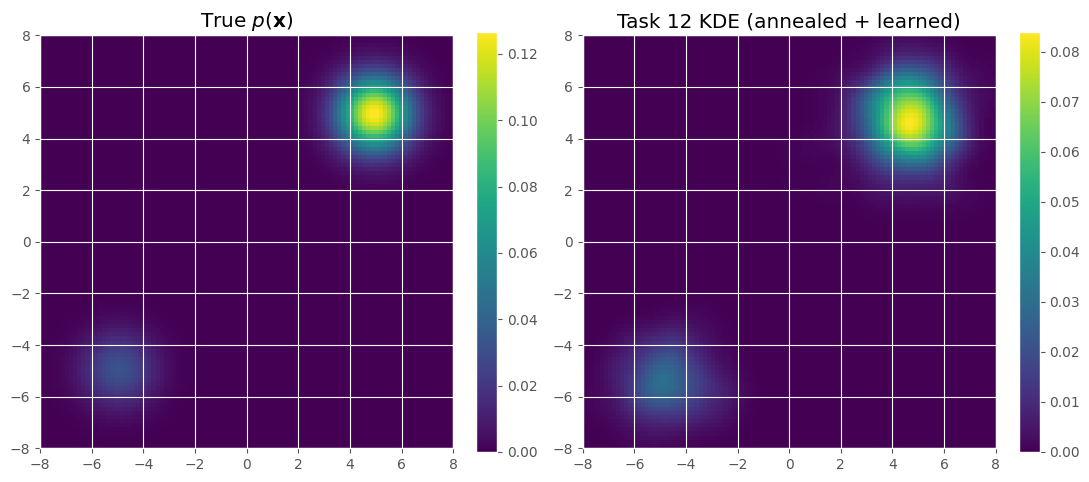

In [19]:
# Task 12 — annealed Langevin with the learned conditional score
def cond_est_score(x, sigma=1):
    used = torch.full((x.shape[0], 1), float(sigma))
    with torch.no_grad():
        return cond_score_net(x, used)

torch.manual_seed(0)
init_uniform = torch.rand(1280, 2) * 16 - 8
samples_t12, snapshots_t12 = annealed_langevin(
    cond_est_score, init_uniform, sigmas_t11.numpy(), epsilon=0.0005, T=100
)

plt.figure(figsize=(6, 6))
plt.scatter(samples_t12[:, 0].numpy(), samples_t12[:, 1].numpy(), s=8, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8); plt.gca().set_aspect('equal')
plt.title('Task 12: annealed Langevin samples (learned cond. score)')
plt.show()

w_small_t12 = ((samples_t12[:, 0] < 0) & (samples_t12[:, 1] < 0)).float().mean().item()
print(f'Task 12: empirical weight on small mode = {w_small_t12:.3f} (true value: 0.20)')

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in enumerate(axes.flat):
    snap = snapshots_t12[i]
    ax.scatter(snap[:, 0].numpy(), snap[:, 1].numpy(), s=6, alpha=0.5)
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect('equal')
    ax.set_title(rf'after step $i={i+1}$, $\sigma={float(sigmas_t11[i]):.2f}$')
fig.suptitle('Task 12: samples after each annealing step (learned scores)')
plt.tight_layout(); plt.show()

p_t12_2d = kde_density(samples_t12, grid100).reshape(100, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, dat, title in zip(axes,
                          [true_p_2d, p_t12_2d],
                          [r'True $p(\mathbf{x})$', 'Task 12 KDE (annealed + learned)']):
    im = ax.imshow(dat.T, origin='lower', extent=[-8, 8, -8, 8], cmap='viridis')
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()


### Conclusion

To conclude, in this HW we have seen the Annealed version of Langevin dynamics that can circumnvent some of the challenges when dealing with complex multi-modal distributions. We have also seen a popular approximation of the score matching objective in Sliced Score Matching, and implemented an annealed version of it to learn a noise-conditional score model. As mentioned in the beginning of this HW, similar models (much deeper + tricks) are currently leading to state-of-the-art performance in image synthesis, and recently also in solving linear inverse problems. For those of you interested in playing with such models, a lot of great resources are publicly available online, for example [this tutorial](https://colab.research.google.com/drive/120kYYBOVa1i0TD85RjlEkFjaWDxSFUx3?usp=sharing) by [Yang Song](https://yang-song.github.io/) who is the author of some key papers in this field.

### References

[1] Song, Y., et al. "Generative modeling by estimating gradients of the data distribution." NeuroIPS (2019). [Link](https://proceedings.neurips.cc/paper/2019/file/3001ef257407d5a371a96dcd947c7d93-Paper.pdf)

[2] Song, Y., et al. "Sliced score matching: A scalable approach to density and score estimation." UAI (2020). [Link](http://proceedings.mlr.press/v115/song20a/song20a.pdf)

[3] Song, Y., et al. "Improved techniques for training score-based generative models." NeuroIPS (2020). [Link](https://proceedings.neurips.cc/paper/2020/file/92c3b916311a5517d9290576e3ea37ad-Paper.pdf)

[4] Song, Y., et al. "Score-based generative modeling through stochastic differential equations." ICLR (2021). [Link](https://arxiv.org/pdf/2011.13456)